# Phase 1: UCI Diabetes 130-US Hospitals - cleaning and exploratory data analysis

Prediction problem: readmission within 30 days (`readmitted == "<30"`), using only information available at the
time of discharge. Protected attribute for fairness evaluation: `race` (kept outside the model inputs).
Main two-group comparison: AfricanAmerican versus Caucasian; all other labels are reported in a separate audit.

Decisions follow the supervisor's instructions: all encounters of one patient stay in the same partition, and
encounters ending in death or hospice are examined and explained. The raw files are never modified.

In [2]:
import csv
import json
import os
import sys

import joblib
import matplotlib
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

SEED = 2026
SPLIT_FRACTIONS = (0.70, 0.15, 0.15)   # train / validation / test, by patient
MAIN_GROUPS = ["Caucasian", "AfricanAmerican"]

if "__file__" in globals():
    ROOT = os.path.abspath(os.path.join(os.path.dirname(os.path.abspath(__file__)), ".."))
else:
    ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
    if not os.path.isdir(os.path.join(ROOT, "data")):
        ROOT = os.getcwd()

RAW_DIR = os.path.join(ROOT, "data", "uci_diabetes", "raw")
PROC_DIR = os.path.join(ROOT, "data", "uci_diabetes", "processed")
OUT = os.path.join(ROOT, "outputs", "uci_diabetes", "phase1")
FIG = os.path.join(OUT, "figures")
REP = os.path.join(ROOT, "reports", "uci_diabetes")
for d in (PROC_DIR, OUT, FIG, REP):
    os.makedirs(d, exist_ok=True)

CLEANING_LOG = []


def log_step(step, description, rows_before, rows_after, decision):
    CLEANING_LOG.append({"step": step, "description": description, "rows_before": rows_before,
                         "rows_after": rows_after, "decision": decision})


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG, name), dpi=150)
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)


def wilson(k, n, z=1.96):
    """95% Wilson interval for a proportion."""
    if n == 0:
        return (np.nan, np.nan)
    p = float(k) / n
    denom = 1 + z * z / n
    centre = (p + z * z / (2.0 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4.0 * n * n)) / denom
    return (centre - half, centre + half)

## 1. Load the raw files (P1-01, P1-02)
Only the literal `?` is treated as missing. Values such as `None` (test not performed) are real categories.

In [3]:
raw_path = os.path.join(RAW_DIR, "diabetic_data.csv")
map_path = os.path.join(RAW_DIR, "IDS_mapping.csv")
raw = pd.read_csv(raw_path, na_values=["?"], keep_default_na=False, low_memory=False,
                  dtype={"payer_code": str, "diag_1": str, "diag_2": str, "diag_3": str,
                         "medical_specialty": str, "race": str})
print("Raw shape (rows, columns):", raw.shape)
print("One row is one hospital encounter.")
raw.head()

Raw shape (rows, columns): (101766, 50)
One row is one hospital encounter.


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,...,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,...,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,...,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,...,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,...,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,...,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 2. Identifiers, duplicates and repeat patients (P1-05)

In [4]:
n_rows = len(raw)
n_enc = raw["encounter_id"].nunique()
n_pat = raw["patient_nbr"].nunique()
enc_per_patient = raw.groupby("patient_nbr").size()
race_labels_per_patient = raw.groupby("patient_nbr")["race"].apply(lambda s: s.fillna("MISSING").nunique())

dup_audit = pd.DataFrame([
    {"item": "rows (encounters)", "value": n_rows},
    {"item": "unique encounter_id", "value": n_enc},
    {"item": "rows sharing an encounter_id with another row", "value": int(raw["encounter_id"].duplicated(keep=False).sum())},
    {"item": "fully duplicated rows", "value": int(raw.duplicated().sum())},
    {"item": "unique patients (patient_nbr)", "value": n_pat},
    {"item": "patients with more than one encounter", "value": int((enc_per_patient > 1).sum())},
    {"item": "largest number of encounters for one patient", "value": int(enc_per_patient.max())},
    {"item": "extra encounters from repeat patients", "value": n_rows - n_pat},
    {"item": "patients whose recorded race label differs between encounters", "value": int((race_labels_per_patient > 1).sum())},
])
dup_audit.to_csv(os.path.join(OUT, "duplicates_audit.csv"), index=False)
print(dup_audit.to_string(index=False))
print("\nDecision: duplicates are reported, not removed. The split is made by patient_nbr so that every encounter of a")
print("patient stays in one partition. Rows are not deleted because of repeat patients.")

                                                         item  value
                                            rows (encounters) 101766
                                          unique encounter_id 101766
                rows sharing an encounter_id with another row      0
                                        fully duplicated rows      0
                                unique patients (patient_nbr)  71518
                        patients with more than one encounter  16773
                 largest number of encounters for one patient     40
                        extra encounters from repeat patients  30248
patients whose recorded race label differs between encounters    249

Decision: duplicates are reported, not removed. The split is made by patient_nbr so that every encounter of a
patient stays in one partition. Rows are not deleted because of repeat patients.


## 3. Discharge disposition: death and hospice (P1-09)
Patients who died or went to hospice cannot be readmitted in the usual sense, so these encounters are examined
and then excluded from the readmission cohort. The descriptions are read from `IDS_mapping.csv`.

In [5]:
def parse_ids_mapping(path):
    sections, current = {}, None
    with open(path, newline="") as f:
        for row in csv.reader(f):
            if not row or all(c.strip() == "" for c in row):
                continue
            if row[0].strip() in ("admission_type_id", "discharge_disposition_id", "admission_source_id"):
                current = row[0].strip()
                sections[current] = {}
                continue
            if current and len(row) >= 2:
                try:
                    sections[current][int(row[0])] = row[1].strip()
                except ValueError:
                    pass
    return sections


ids_map = parse_ids_mapping(map_path)
disp_desc = ids_map.get("discharge_disposition_id", {})
excluded_codes = sorted([c for c, d in disp_desc.items() if "expired" in d.lower() or "hospice" in d.lower()])
if not excluded_codes:
    excluded_codes = [11, 13, 14, 19, 20, 21]
    print("Mapping file could not be parsed; using the documented codes", excluded_codes)

raw["target"] = (raw["readmitted"] == "<30").astype(int)
disp = (raw.groupby("discharge_disposition_id")
        .agg(encounters=("target", "size"), readmitted_30d=("target", "sum")).reset_index())
disp["description"] = disp["discharge_disposition_id"].map(disp_desc)
disp["pct_readmitted_30d"] = (100.0 * disp["readmitted_30d"] / disp["encounters"]).round(2)
disp["excluded"] = disp["discharge_disposition_id"].isin(excluded_codes)
disp.to_csv(os.path.join(OUT, "discharge_disposition_audit.csv"), index=False)
print(disp[disp["excluded"]].to_string(index=False))
print("\nExcluded codes:", excluded_codes)

 discharge_disposition_id  encounters  readmitted_30d                                            description  pct_readmitted_30d  excluded
                       11        1642               0                                                Expired                0.00      True
                       13         399              19                                         Hospice / home                4.76      True
                       14         372              24                             Hospice / medical facility                6.45      True
                       19           8               0               Expired at home. Medicaid only, hospice.                0.00      True
                       20           2               0 Expired in a medical facility. Medicaid only, hospice.                0.00      True

Excluded codes: [11, 13, 14, 19, 20, 21]


## 4. Target, cohort and protected groups (P1-03)

In [6]:
df = raw.copy()
before = len(df)
df = df[~df["discharge_disposition_id"].isin(excluded_codes)].copy()
log_step("cohort", "exclude encounters ending in death or hospice (discharge codes %s)" % excluded_codes, before, len(df),
         "these patients cannot be readmitted; reported in discharge_disposition_audit.csv")
df["race_group"] = df["race"].fillna("Missing")
df["main_cohort"] = df["race_group"].isin(MAIN_GROUPS)

flow = pd.DataFrame([
    {"step": "raw encounters", "encounters": len(raw)},
    {"step": "excluded: discharged dead or to hospice", "encounters": int(len(raw) - len(df))},
    {"step": "cleaned cohort (all race labels, used for the all-groups audit)", "encounters": len(df)},
    {"step": "main two-group cohort (AfricanAmerican + Caucasian)", "encounters": int(df["main_cohort"].sum())},
    {"step": "outside the main cohort (other races and missing race)", "encounters": int((~df["main_cohort"]).sum())},
])
flow.to_csv(os.path.join(OUT, "cohort_flow.csv"), index=False)
print(flow.to_string(index=False))

counts = pd.crosstab(df["race_group"], df["target"], margins=True)
counts.columns = ["not_readmitted_30d", "readmitted_30d", "total"]
counts["pct_readmitted_30d"] = (100.0 * counts["readmitted_30d"] / counts["total"]).round(2)
counts.to_csv(os.path.join(OUT, "counts_by_race_and_target.csv"))
print("\nTarget by race group (all-groups audit):")
print(counts.to_string())

with open(os.path.join(REP, "target_definition.md"), "w") as f:
    f.write("# Target and group definition (UCI Diabetes 130-US Hospitals)\n\n")
    f.write("- Target y = 1 if `readmitted` is `<30` (readmitted within 30 days), y = 0 if `NO` or `>30`.\n")
    f.write("- Prediction point: discharge. The original `readmitted` column is removed from the inputs.\n")
    f.write("- Protected attribute z = `race` (not an input). Main comparison: AfricanAmerican vs Caucasian.\n")
    f.write("- Excluded: encounters with discharge codes %s (expired / hospice).\n\n" % excluded_codes)
    f.write("Class counts in the cleaned cohort: y=1: %d, y=0: %d.\n" % (int(df["target"].sum()), int((1 - df["target"]).sum())))
print(df["target"].value_counts().rename({0: "0 (NO or >30)", 1: "1 (<30)"}).to_string())

                                                           step  encounters
                                                 raw encounters      101766
                        excluded: discharged dead or to hospice        2423
cleaned cohort (all race labels, used for the all-groups audit)       99343
            main two-group cohort (AfricanAmerican + Caucasian)       92992
         outside the main cohort (other races and missing race)        6351

Target by race group (all-groups audit):
                 not_readmitted_30d  readmitted_30d  total  pct_readmitted_30d
race_group                                                                    
AfricanAmerican               16623            2149  18772               11.45
Asian                           563              65    628               10.35
Caucasian                     65664            8556  74220               11.53
Hispanic                       1805             212   2017               10.51
Missing                     

## 5. Missing values and special codes (P1-04)

In [7]:
miss_before = raw.isna().sum()
miss_table = pd.DataFrame({"column": miss_before.index, "missing_before": miss_before.values})
miss_table["pct_before"] = (100.0 * miss_table["missing_before"] / len(raw)).round(2)
HANDLING = {
    "weight": "dropped (about 97% missing)",
    "payer_code": "kept; missing becomes its own category 'Missing'; rare payers grouped using the training set",
    "medical_specialty": "kept; missing becomes 'Missing'; rare specialties grouped using the training set",
    "race": "not a model input; kept as protected attribute (missing labelled 'Missing')",
    "diag_1": "grouped into diagnosis categories; missing becomes 'Missing'",
    "diag_2": "grouped into diagnosis categories; missing becomes 'Missing'",
    "diag_3": "grouped into diagnosis categories; missing becomes 'Missing'",
}
miss_table["handling"] = miss_table["column"].map(HANDLING).fillna("no missing values")
print("Special values: only '?' is used as a placeholder; 'None' in max_glu_serum and A1Cresult means not measured")
print("and is kept as a category. Gender 'Unknown/Invalid' rows:", int((raw["gender"] == "Unknown/Invalid").sum()))
print(miss_table[miss_table["missing_before"] > 0].to_string(index=False))

Special values: only '?' is used as a placeholder; 'None' in max_glu_serum and A1Cresult means not measured
and is kept as a category. Gender 'Unknown/Invalid' rows: 3
           column  missing_before  pct_before                                                                                     handling
             race            2273        2.23                  not a model input; kept as protected attribute (missing labelled 'Missing')
           weight           98569       96.86                                                                  dropped (about 97% missing)
       payer_code           40256       39.56 kept; missing becomes its own category 'Missing'; rare payers grouped using the training set
medical_specialty           49949       49.08             kept; missing becomes 'Missing'; rare specialties grouped using the training set
           diag_1              21        0.02                                 grouped into diagnosis categories; missing becomes 'Missing

## 6. Cleaning and feature preparation (P1-06)
Non-learned transformations only (type conversion, grouping of diagnosis codes, age band to a number).
Anything that depends on the data distribution is fitted on the training partition in section 8.

In [8]:
def icd9_group(code):
    if pd.isna(code):
        return "Missing"
    c = str(code)
    if c.startswith("V") or c.startswith("E"):
        return "Other"
    try:
        v = float(c)
    except ValueError:
        return "Other"
    if 250 <= v < 251:
        return "Diabetes"
    if 390 <= v <= 459 or v == 785:
        return "Circulatory"
    if 460 <= v <= 519 or v == 786:
        return "Respiratory"
    if 520 <= v <= 579 or v == 787:
        return "Digestive"
    if 800 <= v <= 999:
        return "Injury"
    if 710 <= v <= 739:
        return "Musculoskeletal"
    if 580 <= v <= 629 or v == 788:
        return "Genitourinary"
    if 140 <= v <= 239:
        return "Neoplasms"
    return "Other"


before_cols = df.shape[1]
for c in ("diag_1", "diag_2", "diag_3"):
    df[c + "_group"] = df[c].map(icd9_group)
age_order = ["[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)", "[50-60)", "[60-70)", "[70-80)", "[80-90)", "[90-100)"]
df["age_mid"] = df["age"].map({a: 5 + 10 * i for i, a in enumerate(age_order)})
for c in ("admission_type_id", "admission_source_id", "discharge_disposition_id"):
    df[c] = df[c].astype(str)           # codes, not quantities

NUMERIC = ["age_mid", "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
           "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
DRUGS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide", "glipizide",
         "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol", "troglitazone",
         "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin", "glipizide-metformin",
         "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]
DRUGS = [d for d in DRUGS if d in df.columns]
CATEGORICAL = (["gender", "admission_type_id", "discharge_disposition_id", "admission_source_id", "payer_code",
                "medical_specialty", "max_glu_serum", "A1Cresult", "change", "diabetesMed",
                "diag_1_group", "diag_2_group", "diag_3_group"] + DRUGS)
CATEGORICAL = [c for c in CATEGORICAL if c in df.columns]
for c in CATEGORICAL:
    df[c] = df[c].fillna("Missing").astype(str)

log_step("features", "diagnosis codes grouped, age band converted to midpoint, id codes treated as categories, "
         "'weight' removed", len(df), len(df), "weight dropped (97% missing); race kept outside the inputs")
print("Numeric inputs (%d): %s" % (len(NUMERIC), NUMERIC))
print("Categorical inputs (%d)" % len(CATEGORICAL))

Numeric inputs (9): ['age_mid', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
Categorical inputs (36)


## 7. Leakage and timing check (P1-09)
Every column is listed with its role. The model is a discharge-time model, so variables recorded after discharge
are excluded. Diagnosis codes are assumed to be available at discharge in this dataset.

In [9]:
ROLE = {
    "encounter_id": ("excluded", "identifier; never a predictor"),
    "patient_nbr": ("excluded (split key)", "identifier; used only to keep a patient's encounters together"),
    "race": ("protected attribute z", "kept outside the inputs; proxies among the inputs are checked later"),
    "weight": ("excluded", "about 97% missing"),
    "readmitted": ("target source", "defines y; removed from the inputs"),
    "diag_1": ("input (grouped)", "assumed available at discharge; grouped into diagnosis categories"),
    "diag_2": ("input (grouped)", "assumed available at discharge; grouped into diagnosis categories"),
    "diag_3": ("input (grouped)", "assumed available at discharge; grouped into diagnosis categories"),
    "age": ("input (as midpoint)", "known at admission"),
    "discharge_disposition_id": ("input", "known at discharge; death and hospice codes excluded from the cohort"),
}
leak_rows = []
for c in raw.columns:
    if c in ROLE:
        role, why = ROLE[c]
    elif c == "target":
        continue
    elif c in NUMERIC or c in CATEGORICAL:
        role, why = "input", "recorded during the stay or before; available at discharge"
    else:
        role, why = "excluded", "not used"
    leak_rows.append({"column": c, "role": role, "reason": why})
leak = pd.DataFrame(leak_rows)
leak.to_csv(os.path.join(OUT, "leakage_check.csv"), index=False)
with open(os.path.join(REP, "leakage_check.md"), "w") as f:
    f.write("# Leakage and timing check (discharge-time model)\n\n| column | role | reason |\n|---|---|---|\n")
    for r in leak_rows:
        f.write("| %s | %s | %s |\n" % (r["column"], r["role"], r["reason"]))
print(leak["role"].value_counts().to_string())

input                    41
input (grouped)           3
excluded                  2
excluded (split key)      1
protected attribute z     1
input (as midpoint)       1
target source             1


## 8. Patient-safe split and preprocessing fitted on the training set only (P1-08)

In [10]:
rng = np.random.RandomState(SEED)
patients = np.array(sorted(df["patient_nbr"].unique()))
rng.shuffle(patients)
n_p = len(patients)
n_tr = int(SPLIT_FRACTIONS[0] * n_p)
n_va = int(SPLIT_FRACTIONS[1] * n_p)
split_of_patient = pd.Series("test", index=patients)
split_of_patient.iloc[:n_tr] = "train"
split_of_patient.iloc[n_tr:n_tr + n_va] = "val"
df["split"] = df["patient_nbr"].map(split_of_patient)

sets = {s: set(df.loc[df["split"] == s, "patient_nbr"]) for s in ("train", "val", "test")}
overlap = {"train&val": len(sets["train"] & sets["val"]), "train&test": len(sets["train"] & sets["test"]),
           "val&test": len(sets["val"] & sets["test"])}
rows = []
for s in ("train", "val", "test"):
    part = df[df["split"] == s]
    rows.append({"split": s, "encounters": len(part), "patients": part["patient_nbr"].nunique(),
                 "pct_readmitted_30d": round(100.0 * part["target"].mean(), 2),
                 "Caucasian": int((part["race_group"] == "Caucasian").sum()),
                 "AfricanAmerican": int((part["race_group"] == "AfricanAmerican").sum()),
                 "other_or_missing_race": int((~part["main_cohort"]).sum()),
                 "AfricanAmerican_readmitted_30d": int(part.loc[part["race_group"] == "AfricanAmerican", "target"].sum()),
                 "Caucasian_readmitted_30d": int(part.loc[part["race_group"] == "Caucasian", "target"].sum())})
split_audit = pd.DataFrame(rows)
split_audit["patient_overlap_between_splits"] = ""
split_audit.loc[0, "patient_overlap_between_splits"] = json.dumps(overlap)
split_audit.to_csv(os.path.join(OUT, "split_audit.csv"), index=False)
print(split_audit.drop(columns=["patient_overlap_between_splits"]).to_string(index=False))
print("Patients shared between partitions:", overlap)
assert sum(overlap.values()) == 0, "a patient appears in more than one partition"

split  encounters  patients  pct_readmitted_30d  Caucasian  AfricanAmerican  other_or_missing_race  AfricanAmerican_readmitted_30d  Caucasian_readmitted_30d
train       69769     48993               11.51      52078            13242                   4449                            1525                      6065
  val       14668     10498               11.06      10902             2797                    969                             332                      1188
 test       14906     10499               11.15      11240             2733                    933                             292                      1303
Patients shared between partitions: {'train&val': 0, 'train&test': 0, 'val&test': 0}


In [11]:
main = df[df["main_cohort"]].copy()
train = main[main["split"] == "train"]


def top_categories(series, k):
    return list(series.value_counts().head(k).index)


TOP = {"medical_specialty": top_categories(train["medical_specialty"], 10),
       "payer_code": top_categories(train["payer_code"], 8)}
for col, keep in TOP.items():
    keep = set(keep) | {"Missing"}
    main[col] = main[col].where(main[col].isin(keep), "Other")

constant_cols = [c for c in CATEGORICAL if main.loc[main["split"] == "train", c].nunique() <= 1]
cat_cols = [c for c in CATEGORICAL if c not in constant_cols]
print("Columns constant in the training set (dropped):", constant_cols)

pre = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
X_cols = NUMERIC + cat_cols
train = main[main["split"] == "train"]
pre.fit(train[X_cols])
try:
    feature_names = list(pre.get_feature_names_out())
except AttributeError:
    feature_names = ["f%d" % i for i in range(pre.transform(train[X_cols].head(2)).shape[1])]

for s in ("train", "val", "test"):
    part = main[main["split"] == s]
    Xs = pre.transform(part[X_cols])
    Xs = sp.csr_matrix(Xs)
    assert not np.isnan(Xs.data).any(), "NaN after preprocessing"
    sp.save_npz(os.path.join(PROC_DIR, "X_%s.npz" % s), Xs)
    np.save(os.path.join(PROC_DIR, "y_%s.npy" % s), part["target"].values.astype(np.int8))
    np.save(os.path.join(PROC_DIR, "z_%s.npy" % s), (part["race_group"] == "AfricanAmerican").astype(np.int8).values)
    part[["encounter_id", "patient_nbr", "race_group", "target"]].to_csv(os.path.join(PROC_DIR, "ids_%s.csv" % s), index=False)
    print("%-5s X shape %s | readmitted 30d: %d of %d" % (s, Xs.shape, part["target"].sum(), len(part)))

joblib.dump(pre, os.path.join(PROC_DIR, "preprocessor_main.joblib"))
config = {"seed": SEED, "split_fractions": SPLIT_FRACTIONS, "main_groups": MAIN_GROUPS, "excluded_discharge_codes": excluded_codes,
          "numeric": NUMERIC, "categorical": cat_cols, "dropped_constant": constant_cols,
          "top_categories": TOP, "n_features_after_encoding": len(feature_names),
          "z_encoding": "1 = AfricanAmerican, 0 = Caucasian"}
with open(os.path.join(PROC_DIR, "preprocessing_config.json"), "w") as f:
    json.dump(config, f, indent=2)
with open(os.path.join(PROC_DIR, "feature_names.json"), "w") as f:
    json.dump(feature_names, f)
print("Features after encoding:", len(feature_names))

log_step("split", "70/15/15 split by patient_nbr, seed %d" % SEED, len(df), len(df), "no patient appears in two partitions")
log_step("preprocessing", "median imputation + scaling (numeric), 'Missing' + one-hot (categorical), fitted on the main-cohort training set only",
         len(main), len(main), "saved as preprocessor_main.joblib")
pd.DataFrame(CLEANING_LOG).to_csv(os.path.join(OUT, "cleaning_log.csv"), index=False)

miss_after = main[X_cols].isna().sum().sum()
miss_table["missing_after_in_inputs"] = miss_table["column"].map(lambda c: int(main[c].isna().sum()) if c in X_cols else "not an input")
miss_table.to_csv(os.path.join(OUT, "missing_before_after.csv"), index=False)
print("Missing values left in the model inputs:", int(miss_after))

Columns constant in the training set (dropped): ['examide', 'citoglipton', 'metformin-rosiglitazone']
train X shape (65320, 184) | readmitted 30d: 7590 of 65320
val   X shape (13699, 184) | readmitted 30d: 1520 of 13699
test  X shape (13973, 184) | readmitted 30d: 1595 of 13973
Features after encoding: 184
Missing values left in the model inputs: 0


## 9. Exploratory figures (P1-07)

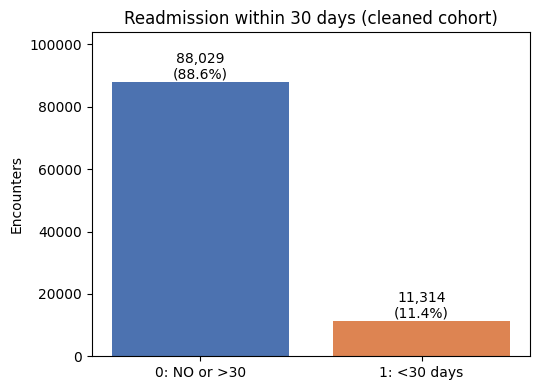

In [12]:
fig, ax = plt.subplots(figsize=(5.5, 4))
vals = df["target"].value_counts().sort_index()
bars = ax.bar(["0: NO or >30", "1: <30 days"], vals.values, color=["#4c72b0", "#dd8452"])
for b, v in zip(bars, vals.values):
    ax.text(b.get_x() + b.get_width() / 2, v, "%s\n(%.1f%%)" % (format(v, ","), 100.0 * v / vals.sum()), ha="center", va="bottom")
ax.set_ylabel("Encounters")
ax.set_title("Readmission within 30 days (cleaned cohort)")
ax.set_ylim(0, vals.max() * 1.18)
save_fig(fig, "fig1_target_distribution.png")

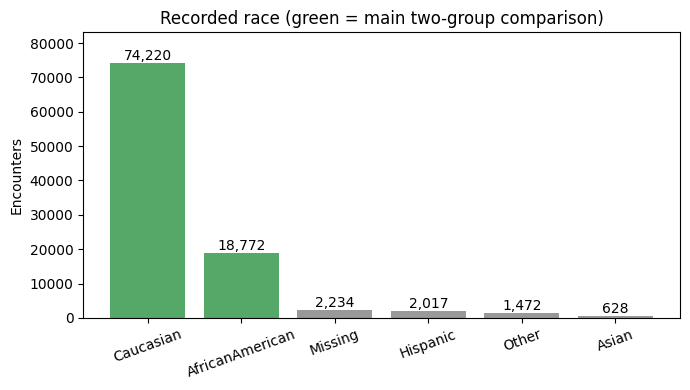

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
rc = df["race_group"].value_counts()
colors = ["#55a868" if r in MAIN_GROUPS else "#999999" for r in rc.index]
bars = ax.bar(rc.index, rc.values, color=colors)
for b, v in zip(bars, rc.values):
    ax.text(b.get_x() + b.get_width() / 2, v, format(v, ","), ha="center", va="bottom")
ax.set_ylabel("Encounters")
ax.set_title("Recorded race (green = main two-group comparison)")
ax.set_ylim(0, rc.max() * 1.12)
plt.setp(ax.get_xticklabels(), rotation=20)
save_fig(fig, "fig2_race_groups.png")

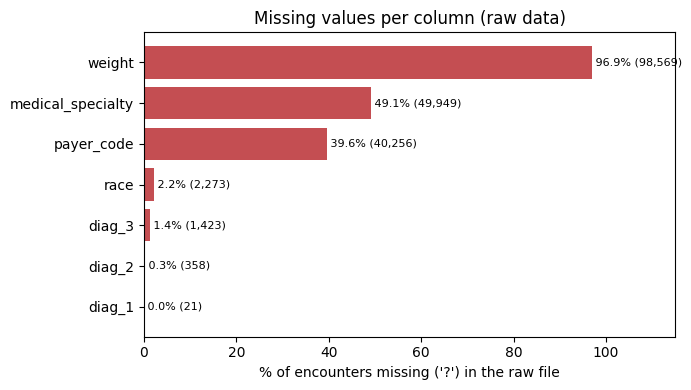

In [14]:
mt = miss_table[miss_table["missing_before"] > 0].sort_values("missing_before", ascending=True)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(mt["column"], mt["pct_before"], color="#c44e52")
for i, (p, n) in enumerate(zip(mt["pct_before"], mt["missing_before"])):
    ax.text(p, i, " %.1f%% (%s)" % (p, format(n, ",")), va="center", fontsize=8)
ax.set_xlabel("% of encounters missing ('?') in the raw file")
ax.set_xlim(0, 115)
ax.set_title("Missing values per column (raw data)")
save_fig(fig, "fig3_missing_values.png")

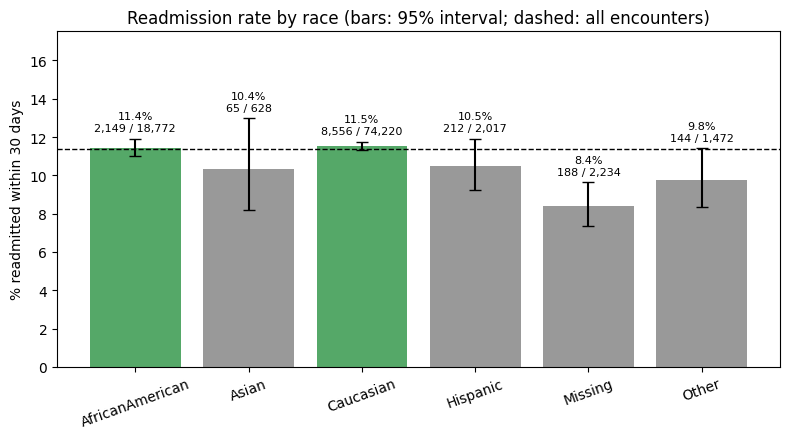

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
order = [g for g in counts.index if g != "All"]
rates, lo, hi, ns = [], [], [], []
for g in order:
    k, n = int(counts.loc[g, "readmitted_30d"]), int(counts.loc[g, "total"])
    l, h = wilson(k, n)
    rates.append(100.0 * k / n); lo.append(100.0 * (k / float(n) - l)); hi.append(100.0 * (h - k / float(n))); ns.append((k, n))
ax.bar(order, rates, yerr=[lo, hi], capsize=4, color=["#55a868" if g in MAIN_GROUPS else "#999999" for g in order])
for i, (r, (k, n)) in enumerate(zip(rates, ns)):
    ax.text(i, r + hi[i] + 0.3, "%.1f%%\n%s / %s" % (r, format(k, ","), format(n, ",")), ha="center", va="bottom", fontsize=8)
ax.axhline(100.0 * df["target"].mean(), color="black", linestyle="--", linewidth=1)
ax.set_ylabel("% readmitted within 30 days")
ax.set_title("Readmission rate by race (bars: 95% interval; dashed: all encounters)")
ax.set_ylim(0, max(r + h for r, h in zip(rates, hi)) * 1.35)
plt.setp(ax.get_xticklabels(), rotation=20)
save_fig(fig, "fig4_readmission_by_race.png")

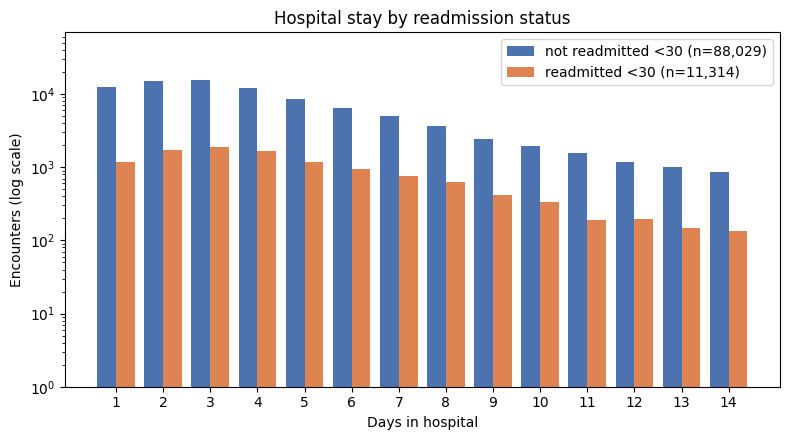

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
days = np.arange(1, 15)
width = 0.4
for shift, label, color, sub in [(-width / 2, "not readmitted <30", "#4c72b0", df[df["target"] == 0]),
                                 (width / 2, "readmitted <30", "#dd8452", df[df["target"] == 1])]:
    cnt = sub["time_in_hospital"].value_counts().reindex(days).fillna(0)
    ax.bar(days + shift, cnt.values, width=width, color=color, label="%s (n=%s)" % (label, format(len(sub), ",")))
ax.set_xlabel("Days in hospital")
ax.set_ylabel("Encounters (log scale)")
ax.set_yscale("log")
ax.set_xticks(days)
ax.set_ylim(1, df["time_in_hospital"].value_counts().max() * 4)
ax.set_title("Hospital stay by readmission status")
ax.legend(loc="upper right")
save_fig(fig, "fig5_stay_by_readmission.png")

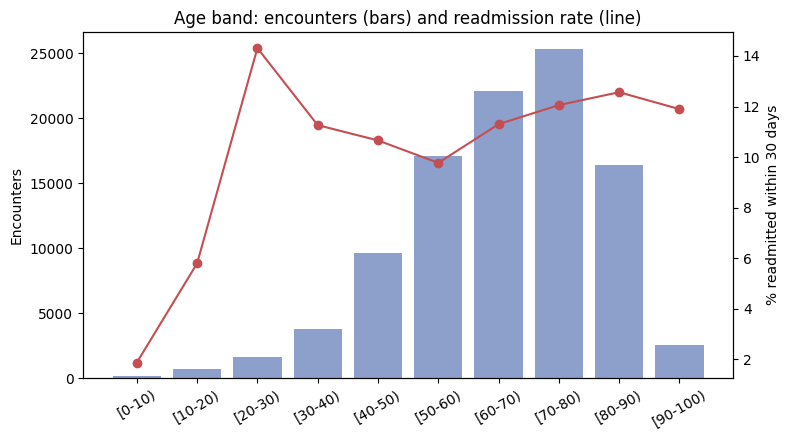

In [17]:
ag = df.groupby("age").agg(n=("target", "size"), k=("target", "sum")).reindex(age_order)
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.bar(range(len(ag)), ag["n"], color="#8da0cb")
ax1.set_xticks(range(len(ag)))
ax1.set_xticklabels(ag.index, rotation=30)
ax1.set_ylabel("Encounters")
ax2 = ax1.twinx()
ax2.plot(range(len(ag)), 100.0 * ag["k"] / ag["n"], color="#c44e52", marker="o")
ax2.set_ylabel("% readmitted within 30 days")
ax1.set_title("Age band: encounters (bars) and readmission rate (line)")
save_fig(fig, "fig6_age_and_readmission.png")

## 10. Summary values for the written EDA report (P1-10)

In [18]:
summary = {
    "raw_encounters": int(len(raw)), "raw_patients": int(n_pat),
    "excluded_death_hospice_encounters": int(len(raw) - len(df)),
    "cleaned_encounters": int(len(df)), "main_cohort_encounters": int(df["main_cohort"].sum()),
    "readmitted_30d_cleaned": int(df["target"].sum()),
    "pct_readmitted_30d_cleaned": round(100.0 * df["target"].mean(), 2),
    "patients_with_inconsistent_race_label": int((race_labels_per_patient > 1).sum()),
    "n_features_after_encoding": len(feature_names),
}
for g in MAIN_GROUPS:
    part = df[df["race_group"] == g]
    summary["%s_encounters" % g] = int(len(part))
    summary["%s_readmitted_30d" % g] = int(part["target"].sum())
    summary["%s_pct_readmitted_30d" % g] = round(100.0 * part["target"].mean(), 2)
with open(os.path.join(OUT, "EDA_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))
print("Outputs written to", os.path.relpath(OUT, ROOT), "and", os.path.relpath(PROC_DIR, ROOT))

{
  "raw_encounters": 101766,
  "raw_patients": 71518,
  "excluded_death_hospice_encounters": 2423,
  "cleaned_encounters": 99343,
  "main_cohort_encounters": 92992,
  "readmitted_30d_cleaned": 11314,
  "pct_readmitted_30d_cleaned": 11.39,
  "patients_with_inconsistent_race_label": 249,
  "n_features_after_encoding": 184,
  "Caucasian_encounters": 74220,
  "Caucasian_readmitted_30d": 8556,
  "Caucasian_pct_readmitted_30d": 11.53,
  "AfricanAmerican_encounters": 18772,
  "AfricanAmerican_readmitted_30d": 2149,
  "AfricanAmerican_pct_readmitted_30d": 11.45
}
Outputs written to outputs\uci_diabetes\phase1 and data\uci_diabetes\processed
